Tutorial: NAFEMS spherical cap restricted to axisymmetric deformations
===

The clamped spherical cap under a central point load of the tutorial
[*Shells pressed down by a prescribed displacement, Riks'
method*](tut-prescribed-displacement-dome-riks.ipynb) is an axisymmetric benchmark. The
3D quarter model of that tutorial, with the co-rotational kinematics, leaves
the axisymmetric path just after the limit load through a
$\cos 2\varphi$ mode, with a snap-back of the prescribed crown deflection,
which an axisymmetric reference cannot have. Here the same co-rotational
shell elements are restricted to the axisymmetric deformations with a
linear map $\boldsymbol{u} = \boldsymbol{T} \boldsymbol{q}$ from three
degrees-of-freedom per ring to the nodal ones, built from the public API,
and the path is compared with the axisymmetric references.

References:

- Lyons, P. and Holsgrove, S., *Finite Element Benchmarks for 2D Beams and
  Axisymmetric Shells Involving Geometric Non-Linearity*, NAFEMS, 2005 (no
  DOI), the benchmark, tabulated in the open verification model COMSOL,
  *Spherical Cap with Central Point Load*, COMSOL Multiphysics 6.4,
  Application Library, Structural Mechanics Module, Verification Examples,
  [doc.comsol.com](https://doc.comsol.com/6.4/doc/com.comsol.help.models.sme.spherical_cap_with_central_point_load/models.sme.spherical_cap_with_central_point_load.pdf):
  the problem on p. 2, a 2D axisymmetric model (Model Wizard, p. 9), the
  parameters and nondimensional variables on p. 9, the reference and COMSOL
  shell results in Tables 3 and 4, p. 7, and the COMSOL shell with 16
  elements in Fig. 3, p. 5, whose annotations give the crown load at the
  crown displacements -4.7, -5.2 and -5.8 m (Results, pp. 21-22). The shell
  of COMSOL has the mid-surface radius $a + t_h/2$: its arc has the radius
  $a + t_h$ with a layer of thickness $t_h$ inwards (Geometry 1, p. 10), and
  the shell is offset to put its top surface on that arc (Thickness and
  Offset 1, pp. 13-14).
- Riks, E., An incremental approach to the solution of snapping and
  buckling problems, *International Journal of Solids and Structures*,
  15(7), 529-551, 1979,
  [doi:10.1016/0020-7683(79)90081-7](https://doi.org/10.1016/0020-7683(79)90081-7),
  the arc-length method.
- Felippa, C. A. and Haugen, B., A unified formulation of small-strain
  corotational finite elements: I. Theory, *Computer Methods in Applied
  Mechanics and Engineering*, 194(21-24), 2285-2335, 2005,
  [doi:10.1016/j.cma.2004.07.035](https://doi.org/10.1016/j.cma.2004.07.035),
  the co-rotational formulation of `pyfe3d.corotational`, whose nodal
  rotations are total rotation vectors.

The model is built by the functions `polar_cap`, `axisymmetric_T`,
`Restricted` and `run_cap_axisymmetric` of
`tests/test_dome_prescribed_displacement.py`, which also runs the main
checks of this notebook as tests. The cells below run in about two minutes.

In [1]:
import os
import sys
import time
from types import SimpleNamespace
sys.path.insert(0, os.path.join('..', '..'))
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import spsolve

import pyfe3d
from pyfe3d import DOF
from pyfe3d.corotational import CorotationalModel, expso3
from test_dome_prescribed_displacement import (CAP, FIG3_SHELL_COMSOL16,
    TABLE_SHELL_REF, TABLE_SHELL_COMSOL16, polar_cap, axisymmetric_T,
    Restricted, run_cap_axisymmetric, run_cap_corotational,
    prescribed_path_corotational, limit_points, load_factor, branches,
    _symmetry)

print('pyfe3d', pyfe3d.__version__, 'from', os.path.dirname(pyfe3d.__file__))
a, th, alpha = CAP['a'], CAP['th'], CAP['alpha']
T_START = time.time()

pyfe3d 0.12.0 from C:\Users\saullogiovanip\repos\pyfe3d\doc\source\..\..\pyfe3d


The benchmark
===

Radius $a = 10$ m, thickness $t_h = 0.20384$ m, half-angle $\pi/4$, edge
clamped (p. 2); $E = 210$ GPa, $\nu = 0.3$ (p. 9). The results use the
nondimensional load and crown deflection (p. 9)

$$
F_n = \frac{F a}{2 \pi E t_h^3}, \qquad \frac{w}{t_h}
$$

with $F$ the point load on the whole cap and $w$ the downward deflection of
the crown. The crown deflection is prescribed, without any applied load,
up to $w/t_h = 30$, and the reaction is traced with Riks' method, as in the
dome tutorial. The values compared below are the three points of Fig. 3 of
COMSOL (16 shell elements, `FIG3_SHELL_COMSOL16`): $F_n = 1.806$ at
$w/t_h = 23.06$, near the maximum of the curve of Fig. 4 (p. 6), 1.717 at
25.51, after it, and 2.787 at 28.45, on the stiffening branch of the
inverted cap.

The polar mesh
===

The cap is meshed with `nr` rings at the polar angles
$\beta_i = i \alpha / n_r$ and sectors of angle $\Delta\varphi$: the first
ring is joined to the crown by `Tria3R` triangles and the other rings by
`Quad4R` quadrilaterals. Each quadrilateral, with its nodes at two polar
angles and two azimuths of the sphere, is an isosceles trapezoid, hence
flat, and the mesh is invariant under the rotations by $\Delta\varphi$
about the axis. A quarter with 16 rings and 8 sectors, one sector shaded:

quarter, 16 rings x 8 sectors: 8 Tria3R, 120 Quad4R, 145 nodes, 870 dofs
T: 870 x 46, the crown deflection and (u_r, u_z, theta) of rings 1 to 15


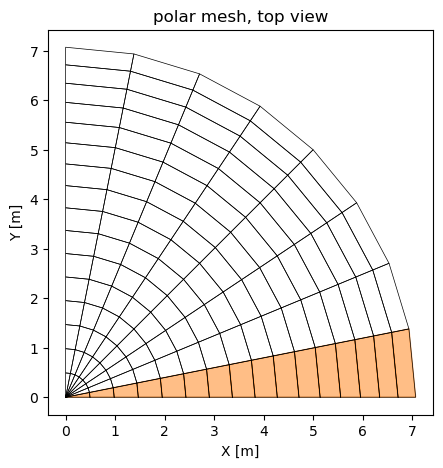

In [2]:
nr, nsec, dphi = 16, 8, np.pi/16
x, prop, elements, ring, azimuth = polar_cap(nr, nsec, dphi, a)
xyz = x.reshape(-1, 3)
T = axisymmetric_T(ring, azimuth, nr)
print('quarter, %d rings x %d sectors: %d Tria3R, %d Quad4R, %d nodes, %d dofs'
      % (nr, nsec, nsec, len(elements) - nsec, len(xyz), x.size//3*DOF))
print('T: %d x %d, the crown deflection and (u_r, u_z, theta) of rings 1 to %d'
      % (T.shape + (nr - 1,)))
fig, ax = plt.subplots(figsize=(5, 5))
for e in elements:
    nodes = [e.n1, e.n2, e.n3] + ([e.n4] if hasattr(e, 'n4') else [])
    P = xyz[nodes + nodes[:1], :2]
    first = np.all(azimuth[nodes[1:]] <= dphi + 1e-12)
    if first:
        ax.fill(P[:, 0], P[:, 1], color='C1', alpha=0.5)
    ax.plot(P[:, 0], P[:, 1], 'k-', lw=0.5)
ax.set_aspect('equal')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_title('polar mesh, top view')
plt.show()

The restriction to axisymmetric deformations
===

A torsionless axisymmetric deformation moves each point within its
meridian plane. A node at the azimuth $\varphi$, with the radial and hoop
directions $\boldsymbol{e}_r = (\cos\varphi, \sin\varphi, 0)$ and
$\boldsymbol{e}_\varphi = (-\sin\varphi, \cos\varphi, 0)$, has the
displacement $u_r \boldsymbol{e}_r + u_z \boldsymbol{e}_z$ and its director
rotates by an angle $\theta$ about $\boldsymbol{e}_\varphi$, the same
$u_r$, $u_z$ and $\theta$ for all the nodes of a ring:

$$
\begin{pmatrix} u_x \\ u_y \\ u_z \\ \psi_x \\ \psi_y \\ \psi_z \end{pmatrix}
=
\begin{bmatrix}
\cos\varphi & 0 & 0 \\
\sin\varphi & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & -\sin\varphi \\
0 & 0 & \cos\varphi \\
0 & 0 & 0
\end{bmatrix}
\begin{pmatrix} u_r \\ u_z \\ \theta \end{pmatrix}
$$

These blocks, assembled for all the nodes, are the columns of
$\boldsymbol{T}$ (`axisymmetric_T`). At the crown only $u_z$ is kept, the
prescribed deflection, with $u_r = \theta = 0$; the last ring is clamped
and has no column.

**Why the map is exact for finite rotations.** The rotational dofs of
`CorotationalModel` are total rotation vectors $\boldsymbol{\psi}$, with
the nodal rotation matrix
$\boldsymbol{R} = \exp(\mathrm{Spin}(\boldsymbol{\psi}))$ (module notes of
`pyfe3d.corotational`). A rotation by $\theta$ about a fixed axis
$\boldsymbol{e}_\varphi$ has the rotation vector
$\theta \boldsymbol{e}_\varphi$ exactly, for any $|\theta| < 2\pi$, so the
map is linear in $\theta$ without approximation. The drilling component,
along the shell normal, is zero: the normal lies in the meridian plane, to
which $\boldsymbol{e}_\varphi$ is normal, before and after the rotation.
Because the map is linear, the restricted model has the internal force
$\boldsymbol{T}^T \boldsymbol{f}_{int}(\boldsymbol{T}\boldsymbol{q})$ and
the tangent stiffness matrix
$\boldsymbol{T}^T \boldsymbol{K}_T(\boldsymbol{T}\boldsymbol{q}) \boldsymbol{T}$,
the exact gradient and Hessian of the strain energy on the subspace; the
class `Restricted` gives them to `Analysis` with the interface of a model.

The rows of $\boldsymbol{T}$ of one node, and a check of the rotation: the
normal of the sphere at that node, rotated with `expso3` by
$\theta \boldsymbol{e}_\varphi$, $\theta = 1.2$ rad, is the normal at the
polar angle $\beta + \theta$ of the same meridian.

In [3]:
k = np.flatnonzero((ring == 5) & np.isclose(azimuth, 3*dphi))[0]
cols = T[DOF*k:DOF*(k + 1)].nonzero()[1]
print('node %d, ring %d, phi = %.4f rad; columns %s of T, rows u_x .. psi_z:'
      % (k, ring[k], azimuth[k], np.unique(cols)))
print(T[DOF*k:DOF*(k + 1)][:, np.unique(cols)].toarray().round(4))
phi = azimuth[k]
e_phi = np.array([-np.sin(phi), np.cos(phi), 0.])
n0 = xyz[k]/np.linalg.norm(xyz[k])
beta = np.arccos(n0[2])
theta = 1.2
n1 = expso3(theta*e_phi) @ n0
n_exact = np.array([np.sin(beta + theta)*np.cos(phi),
                    np.sin(beta + theta)*np.sin(phi), np.cos(beta + theta)])
print('rotated normal %s, expected %s, difference %.1e; component along '
      'e_phi %.1e' % (n1.round(6), n_exact.round(6),
                      np.abs(n1 - n_exact).max(), n1 @ e_phi))
assert np.allclose(n1, n_exact, atol=1e-14)

node 40, ring 5, phi = 0.5890 rad; columns [13 14 15] of T, rows u_x .. psi_z:
[[ 0.8315  0.      0.    ]
 [ 0.5556  0.      0.    ]
 [ 0.      1.      0.    ]
 [ 0.      0.     -0.5556]
 [ 0.      0.      0.8315]
 [ 0.      0.      0.    ]]
rotated normal [0.824945 0.551211 0.125031], expected [0.824945 0.551211 0.125031], difference 4.7e-16; component along e_phi -5.6e-17


Check against the unrestricted model
---

The polar mesh is invariant under the rotations by $\Delta\varphi$, so the
axisymmetric path is also a solution of the unrestricted model with the
same mesh. A quarter with 16 rings and 4 sectors of 22.5 degrees,
unrestricted, with the symmetry conditions on the planes $X = 0$ and
$Y = 0$, is traced up to $w/t_h = 20$, where the meridian has rotated by
about 60 degrees, and compared with one sector of the same mesh restricted
by $\boldsymbol{T}$ (`tests/test_dome_prescribed_displacement.py::test_cap_axisymmetric_map_exact`).

**Tolerance**: $10^{-5}$ of the largest load, the loads being interpolated
at the same deflections.

In [4]:
nr, nsec, dphi = 16, 4, np.pi/8
x, prop, elements, ring, azimuth = polar_cap(nr, nsec, dphi, a)
N = x.size//3*DOF
bk = np.zeros(N, dtype=bool)
for i in np.flatnonzero(ring == nr):
    bk[DOF*i:DOF*(i + 1)] = True
_symmetry(bk, x[0::3], x[1::3])
bk[2] = True  # NOTE crown deflection, node 0
# NOTE what prescribed_path_corotational uses of a model
model = SimpleNamespace(x=x, N=N, elements=elements, prop=prop)
t0 = time.time()
w, F, F_lin, an, cr = prescribed_path_corotational(model, ~bk, 2, 20*th)
t_full = time.time() - t0
w, Fn = w/th, load_factor(F)
t0 = time.time()
w_ax, Fn_ax, an_ax = run_cap_axisymmetric(nr, a, w_max=20., dphi=dphi,
                                          inc=0.02)
t_ax = time.time() - t0
diff = np.abs(np.interp(w, w_ax, Fn_ax) - Fn).max()/Fn.max()
print('unrestricted quarter: %d free dofs, %.1f s; restricted sector: %d '
      'free dofs, %.1f s' % ((~bk).sum(), t_full, 3*(nr - 1), t_ax))
print('largest load difference %.1e of the largest load, F_n = %.4f at '
      'w/th = %.1f' % (diff, Fn[-1], w[-1]))
assert an.increments[-1] == 1. and an_ax.increments[-1] == 1.
assert diff < 1e-5

unrestricted quarter: 360 free dofs, 2.0 s; restricted sector: 45 free dofs, 0.6 s
largest load difference 4.6e-07 of the largest load, F_n = 1.8289 at w/th = 20.0


The difference is of the order of the convergence tolerance of the
solver: the restriction by $\boldsymbol{T}$ changes nothing along the
axisymmetric path, including the large rotations.

Sector angle and cost
---

Since every sector deforms identically, one sector carries the whole
axisymmetric solution, and the reaction of the cap is that of the sector
times $2\pi/\Delta\varphi$. A quarter of $n_s$ sectors restricted by
$\boldsymbol{T}$ gives the same path at $n_s$ times the cost; measured
separately on 2026-10-31 with 32 rings: 8 sectors of 11.25 degrees, 15.8 s,
and one sector of 11.25 degrees, 1.9 s, both with the limit load 1.8771 at
$w/t_h = 22.87$. A single sector is used below.

The sector angle sets the facet error of the hoop direction: the chord of a
sector is shorter than its arc by $\Delta\varphi^2/24$, and the change of
the rotation vectors between the two sides of the sector gives the hoop
curvature as a finite difference. Its effect on the limit load, with 64
rings and $R = a + t_h/2$, and the aspect ratios (meridian length over hoop
width) of the elements at the crown and at the edge:

In [5]:
R = a + th/2
L = R*alpha/64
print('%8s %10s %8s %16s %16s %8s' % ('dphi', 'limit F_n', 'w/th',
      'aspect, ring 1-2', 'aspect, edge', 'time'))
lim_dphi = {}
for deg in [0.5, 1., 4., 16.]:
    t0 = time.time()
    w, Fn, an = run_cap_axisymmetric(64, R, dphi=np.radians(deg), inc=0.02)
    dt = time.time() - t0
    (F_max, w_max), _ = limit_points(w, Fn, 24.5)
    lim_dphi[deg] = F_max
    width = lambda b: 2*R*np.sin(b)*np.sin(np.radians(deg)/2)
    print('%6.1f deg %10.4f %8.2f %16.1f %16.2f %6.1f s' % (
        deg, F_max, w_max, L/width(1.5*alpha/64), L/width(alpha), dt))
assert abs(lim_dphi[0.5]/lim_dphi[1.] - 1) < 2e-4
assert abs(lim_dphi[4.]/lim_dphi[1.] - 1) < 2e-3

    dphi  limit F_n     w/th aspect, ring 1-2     aspect, edge     time


   0.5 deg     1.8348    23.21             76.4             1.99    1.8 s


   1.0 deg     1.8350    23.21             38.2             0.99    1.8 s


   4.0 deg     1.8371    23.21              9.6             0.25    1.7 s


  16.0 deg     1.8543    23.16              2.4             0.06    1.9 s


The limit load grows by 0.1 % from 1 to 4 degrees and by 1.0 % from 1 to
16 degrees, roughly as $\Delta\varphi^2$. With 1 degree the elements next
to the crown are long and narrow, aspect ratio 38, but their deformation is
the axisymmetric one imposed by $\boldsymbol{T}$, and halving the sector
angle to 0.5 degree changes the limit load by less than
$2 \times 10^{-4}$: $\Delta\varphi = 1$ degree is used below.

The path, the mesh and the radius
===

The path up to $w/t_h = 30$, with Riks' method of arc length 0.01, for 32
to 256 rings and the two radii of the mid-surface: $a$, the radius of the
benchmark, and $a + t_h/2$, the geometry of the COMSOL shell. In addition,
the transverse shear stiffness is multiplied by 1000, the Kirchhoff limit,
for 128 rings and $R = a + t_h/2$.

In [6]:
runs = {}
cases = ([('a + th/2', nr, 1.) for nr in (32, 64, 128, 256)]
         + [('a', nr, 1.) for nr in (64, 128, 256)]
         + [('a + th/2', 128, 1000.)])
print('%-9s %5s %6s | %16s | %16s | %4s | %7s %7s | %8s | %5s' % (
      'R', 'rings', 'shear', 'limit F_n, w/th', 'minimum after', 'mono',
      'F(23.06)', 'F(25.51)', 'w(2.787)', 't [s]'))
for label, nr, shear in cases:
    R = a + th/2 if label == 'a + th/2' else a
    t0 = time.time()
    w, Fn, an = run_cap_axisymmetric(nr, R, shear_factor=shear)
    dt = time.time() - t0
    assert an.increments[-1] == 1.
    (F_max, w_max), (F_min, w_min) = limit_points(w, Fn, 24.5)
    stiff = w > w_min
    w_3 = np.interp(FIG3_SHELL_COMSOL16[2, 0], Fn[stiff], w[stiff])
    F_C = np.interp(FIG3_SHELL_COMSOL16[:2, 1], w, Fn)
    mono = bool(np.all(np.diff(w) > 0))
    runs[label, nr, shear] = dict(w=w, F=Fn, lim=(F_max, w_max),
                                  min=(F_min, w_min), w_3=w_3, F_C=F_C,
                                  mono=mono)
    print('%-9s %5d %6g | %7.4f at %5.2f | %7.4f at %5.2f | %4s | %7.4f %7.4f |'
          ' %8.3f | %5.1f' % (label, nr, shear, F_max, w_max, F_min, w_min,
                              mono, *F_C, w_3, dt))
print('COMSOL, 16 shell elements, Fig. 3: %.3f at %.2f, %.3f at %.2f, %.3f '
      'at %.2f' % tuple(FIG3_SHELL_COMSOL16.ravel()))
assert all(r['mono'] for r in runs.values())

R         rings  shear |  limit F_n, w/th |    minimum after | mono | F(23.06) F(25.51) | w(2.787) | t [s]


a + th/2     32      1 |  1.8579 at 23.06 |  1.7342 at 25.73 | True |  1.8578  1.7379 |   28.518 |   2.3


a + th/2     64      1 |  1.8350 at 23.21 |  1.7332 at 25.75 | True |  1.8348  1.7363 |   28.613 |   3.5


a + th/2    128      1 |  1.8293 at 23.30 |  1.7329 at 25.83 | True |  1.8284  1.7366 |   28.687 |   6.7


a + th/2    256      1 |  1.8278 at 23.33 |  1.7324 at 25.84 | True |  1.8265  1.7375 |   28.740 |  12.8


a            64      1 |  1.8387 at 22.91 |  1.7403 at 25.46 | True |  1.8383  1.7410 |   28.318 |   3.4


a           128      1 |  1.8331 at 23.00 |  1.7399 at 25.54 | True |  1.8329  1.7399 |   28.391 |   6.6


a           256      1 |  1.8316 at 23.04 |  1.7395 at 25.55 | True |  1.8316  1.7396 |   28.444 |  12.6


a + th/2    128   1000 |  1.8690 at 22.86 |  1.7098 at 25.73 | True |  1.8676  1.7136 |   28.397 |   6.4
COMSOL, 16 shell elements, Fig. 3: 1.806 at 23.06, 1.717 at 25.51, 2.787 at 28.45


- **No snap-back.** On every mesh the crown deflection grows monotonically
  up to $w/t_h = 30$: restricted to the axisymmetric deformations, the
  path has the limit load, the softening after it and the stiffening of the
  inverted cap, with a single branch, as the axisymmetric references.
- **Convergence of the limit load.** With $R = a + t_h/2$: 1.858, 1.835,
  1.829 and 1.828 with 32, 64, 128 and 256 rings, the differences falling
  by about 4 at each refinement, second order. With $R = a$ the limit load
  is 0.2 % higher, 1.832 with 256 rings: the radius matters little here.
  The minimum after the limit converges faster, to 1.732 ($a + t_h/2$) and
  1.740 ($a$).
- **The deflections drift with the mesh.** The deflection at the limit load
  grows from 23.06 to 23.33 with $R = a + t_h/2$, and at the load 2.787
  from 28.52 to 28.74, without converging, while in the Kirchhoff limit
  they converge (measured separately on 2026-10-31 with 64, 128 and 256
  rings: the limit at $w/t_h$ = 22.83, 22.85 and 22.85, and $w/t_h$ =
  28.38, 28.40 and 28.40 at the load 2.787). The next section explains
  why.

The point load on a shear-deformable shell
---

Near the load, the transverse shear force is $Q = F/(2\pi r)$, from the
vertical equilibrium of a disc of radius $r$, and with the shear stiffness
$\kappa G t_h$ the shear deflection grows as
$F \ln(1/r)/(2\pi\kappa G t_h)$: the deflection under a point load of a
shell with transverse shear is singular, and a mesh reaches the singularity
down to its crown element. Halving the crown element adds (derived here)

$$
\Delta\left(\frac{w}{t_h}\right) = F_n \, \frac{t_h}{a} \,
\frac{2 (1 + \nu)}{\kappa} \ln 2 = 0.0441 \, F_n, \qquad \kappa = 5/6
$$

The linear crown compliance of the restricted model, $(w/t_h)/F_n$, shows
it:

In [7]:
def compliance(nr, shear):
    x, prop, elements, ring, azimuth = polar_cap(nr, 1, np.radians(1.),
                                                 a + th/2, shear)
    cr = CorotationalModel(x, x.size//3*DOF)
    for elem in elements:
        cr.add(elem, prop, kinematics='corotational')
    K = Restricted(cr, axisymmetric_T(ring, azimuth, nr)).KC0.tocsc()
    q = np.zeros(K.shape[0])
    q[0] = -th
    q[1:] = spsolve(K[1:, 1:], -K[1:, :1] @ q[:1])
    return 1/load_factor(-(K @ q)[0]*2*np.pi/np.radians(1.))

kappa, nu = 5/6, CAP['nu']
dC = th/a*2*(1 + nu)/kappa*np.log(2)
meshes = [16, 32, 64, 128, 256, 512]
C = {s: np.array([compliance(nr, s) for nr in meshes]) for s in (1., 1000.)}
print('derived increment per halving: %.4f' % dC)
print('%6s %14s %10s %14s %10s' % ('rings', 'shear: C', 'increment',
                                   'x1000: C', 'increment'))
for i, nr in enumerate(meshes):
    inc = ['%10.4f' % np.diff(C[s])[i - 1] if i else '%10s' % '-'
           for s in (1., 1000.)]
    print('%6d %14.4f %s %14.4f %s' % (nr, C[1.][i], inc[0], C[1000.][i],
                                       inc[1]))
assert abs(np.diff(C[1.])[-1]/dC - 1) < 0.03
assert np.diff(C[1000.])[-1] < 0.001

derived increment per halving: 0.0441
 rings       shear: C  increment       x1000: C  increment
    16         2.6126          -         2.4665          -
    32         2.7663     0.1537         2.5764     0.1100
    64         2.8419     0.0756         2.6081     0.0316
   128         2.8948     0.0529         2.6169     0.0088
   256         2.9413     0.0465         2.6194     0.0025
   512         2.9861     0.0448         2.6201     0.0007


With the actual shear stiffness the compliance keeps growing by an amount
that tends to the derived 0.0441 per halving; in the Kirchhoff limit it
converges. The crown deflection of the shear-deformable shell is therefore
not a converged quantity: the loads converge, but a path is shifted along
$w$ by an amount that depends on the crown element, its size and its
formulation. The comparisons below take this into account.

Comparison with COMSOL and with an independent axisymmetric shell
===

As an independent check, written for this comparison and not part of
pyfe3d, a geometrically exact axisymmetric shell was coded separately
(derived here): Reissner kinematics of the meridian, with the stretching
$\varepsilon_s$, the hoop strain $r/r_0 - 1$, the meridional and hoop
curvatures and the transverse shear strain of a meridian of rotating
sections, small strains, two-node elements with one-point integration,
160 elements refined towards the crown with $\beta = \alpha \xi^{1.5}$,
the same nondimensional variables, traced by pseudo-arc-length
continuation. Its results, run on 2026-10-30:

| $R$ | transverse shear | limit $F_n$, $w/t_h$ | minimum after, $w/t_h$ | $w/t_h$ at $F_n = 2.787$ |
|---|---|---|---|---|
| $a$ | $\kappa G t_h$ | 1.8345, 23.38 | 1.7398, 25.84 | 28.99 |
| $a + t_h/2$ | $\kappa G t_h$ | 1.8308, 23.61 | 1.7327, 26.12 | 29.29 |
| $a$ | times 1000 | 1.8735, 22.61 | 1.7168, 25.44 | 28.11 |
| $a + t_h/2$ | times 1000 | 1.8696, 22.85 | 1.7095, 25.71 | 28.41 |

The same grading of the rings, 160 rings with `grading=1.5`, in the
restricted pyfe3d model:

In [8]:
AXI = {1.: (1.8308, 23.61, 1.7327, 26.12, 29.29),
       1000.: (1.8696, 22.85, 1.7095, 25.71, 28.41)}
for shear in (1., 1000.):
    w, Fn, an = run_cap_axisymmetric(160, a + th/2, shear_factor=shear,
                                     grading=1.5)
    (F_max, w_max), (F_min, w_min) = limit_points(w, Fn, 24.5)
    stiff = w > w_min
    w_3 = np.interp(FIG3_SHELL_COMSOL16[2, 0], Fn[stiff], w[stiff])
    runs['graded', 160, shear] = dict(w=w, F=Fn)
    ref = AXI[shear]
    print('shear x%-5g pyfe3d: limit %.4f at %.2f, minimum %.4f at %.2f, '
          'w/th at 2.787: %.2f' % (shear, F_max, w_max, F_min, w_min, w_3))
    print('%13s axisymmetric shell: %.4f at %.2f, %.4f at %.2f, %.2f' % (('',)
                                                                         + ref))
    assert abs(F_max/ref[0] - 1) < 0.002 and abs(F_min/ref[2] - 1) < 0.002

shear x1     pyfe3d: limit 1.8301 at 23.40, minimum 1.7328 at 25.85, w/th at 2.787: 28.85
              axisymmetric shell: 1.8308 at 23.61, 1.7327 at 26.12, 29.29


shear x1000  pyfe3d: limit 1.8697 at 22.92, minimum 1.7103 at 25.65, w/th at 2.787: 28.41
              axisymmetric shell: 1.8696 at 22.85, 1.7095 at 25.71, 28.41


- In the Kirchhoff limit the restricted pyfe3d model and the independent
  axisymmetric shell coincide: limit loads 1.8697 at $w/t_h = 22.92$
  against 1.8696 at 22.85, minima 1.7103 at 25.65 against 1.7095 at 25.71
  (sampled points of the pyfe3d path, interpolated extrema of the
  independent shell), and the deflection at the load 2.787, 28.41 in both.
- With the transverse shear the loads still agree within 0.05 %, 1.8301
  and 1.7328 against 1.8308 and 1.7327, but the pyfe3d path lies 0.2 to
  0.45 to the left in $w/t_h$, at the same crown grading: the two crown elements, a
  `Tria3R` fan and a two-node axisymmetric element, resolve the singular
  shear deflection differently. The difference vanishes in the Kirchhoff
  limit, so it is the shear singularity, not the large rotations.

Against COMSOL's shell with 16 elements, Fig. 3: at $w/t_h = 23.06$ the
load with transverse shear is 1.827 (256 rings), 1.1 % above 1.806, and
in the Kirchhoff limit 1.868, 3.4 % above; at 25.51 the load is 1.738 with
shear, 1.2 % above 1.717, and 1.714 in the Kirchhoff limit,
0.2 % below. The deflections of COMSOL at the loads of Table 4 on the
rising branch, 2.445 to 21.64, are within 0.5 % of those of the
restricted model with transverse shear and 256 rings (next cell). The
COMSOL values are those of a 16-element mesh, whose element order is not
stated in the model document; its limit load is not converged to better
than the 1 % found here.

**Tolerance**: the limit load with 256 rings within 1.5 % of 1.806, the
measured +1.2 % plus the scatter between COMSOL meshes; the load at 25.51
within 2 %.

In [9]:
p = runs['a + th/2', 256, 1.]
i = np.argmax(p['F'])
i_lim = np.argmax(np.where(p['w'] < 24.5, p['F'], -1))
w_C16 = np.interp(TABLE_SHELL_COMSOL16[:5, 0], p['F'][:i_lim + 1],
                  p['w'][:i_lim + 1])
print('rising branch, w/th at the loads of Table 4 (COMSOL, 16 elements):')
for (F, wc), wp in zip(TABLE_SHELL_COMSOL16[:5], w_C16):
    print('  F_n = %.3f: COMSOL %.3f, restricted pyfe3d %.3f (%+.1f %%)' % (
        F, wc, wp, 100*(wp/wc - 1)))
rel_lim = p['lim'][0]/FIG3_SHELL_COMSOL16[0, 0] - 1
rel_2 = p['F_C'][1]/FIG3_SHELL_COMSOL16[1, 0] - 1
print('limit load %.4f, %+.1f %% on 1.806; load at 25.51 %.4f, %+.1f %% on '
      '1.717' % (p['lim'][0], 100*rel_lim, p['F_C'][1], 100*rel_2))
assert np.all(np.abs(w_C16/TABLE_SHELL_COMSOL16[:5, 1] - 1) < 0.01)
assert abs(rel_lim) < 0.015
assert abs(rel_2) < 0.02

rising branch, w/th at the loads of Table 4 (COMSOL, 16 elements):
  F_n = 0.332: COMSOL 2.445, restricted pyfe3d 2.448 (+0.1 %)
  F_n = 0.580: COMSOL 6.800, restricted pyfe3d 6.783 (-0.3 %)
  F_n = 0.994: COMSOL 13.800, restricted pyfe3d 13.784 (-0.1 %)
  F_n = 1.502: COMSOL 18.945, restricted pyfe3d 18.946 (+0.0 %)
  F_n = 1.757: COMSOL 21.640, restricted pyfe3d 21.523 (-0.5 %)
limit load 1.8278, +1.2 % on 1.806; load at 25.51 1.7375, +1.2 % on 1.717


The unrestricted quarter model
===

For comparison, the quarter model of the dome tutorial
(`run_cap_corotational`), unrestricted, with its mesh of three blocks of
8x8 `Quad4R` and $R = a$, traced with the same kinematics. Its limit load
is that of a coarse mesh, 1.956 with 8x8 cells, decreasing to 1.895 and
1.873 with 12x12 and 16x16 cells (`test_cap_corotational`); just after the
limit load the deflection turns back, where the path leaves the
axisymmetric deformations.

unrestricted quarter, 8x8 cells per block: 222 increments, 26 s; limit load 1.9555 at w/th = 23.50; w/th decreases after 23.93 and increases again from 26.03


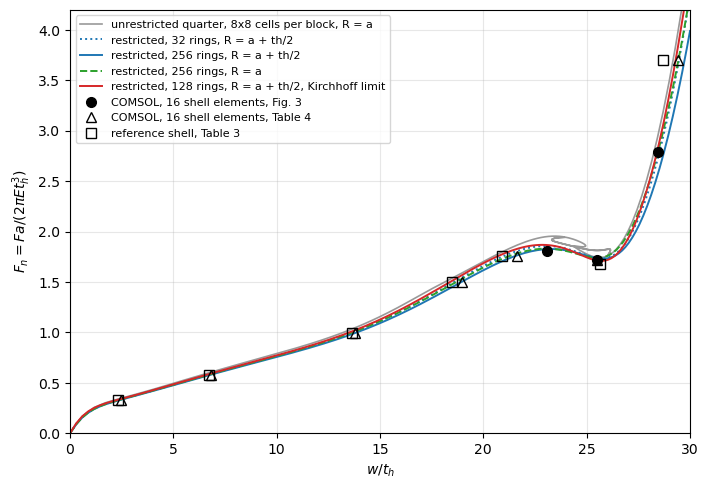

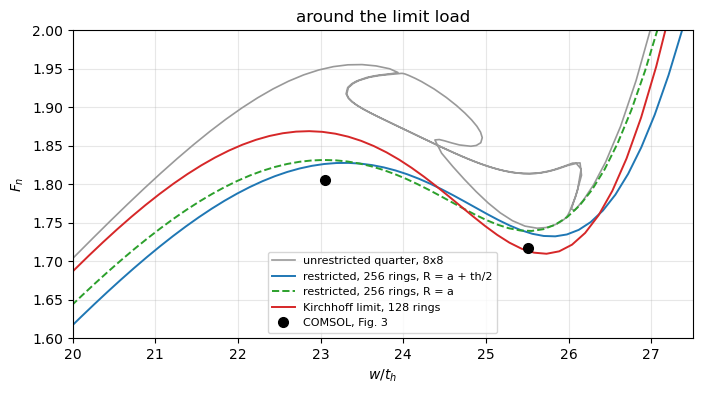

total run time of the notebook: 106 s


In [10]:
t0 = time.time()
wq, Fq, slope, anq, modelq, dofw = run_cap_corotational(8, a)
first, last = branches(wq)
i = np.argmax(Fq[first])
Fq_max, wq_max = Fq[first][i], wq[first][i]
print('unrestricted quarter, 8x8 cells per block: %d increments, %.0f s; '
      'limit load %.4f at w/th = %.2f; w/th decreases after %.2f and '
      'increases again from %.2f' % (len(wq), time.time() - t0, Fq_max,
                                     wq_max, wq[first][-1], wq[last][0]))
assert np.any(np.diff(wq) < 0)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(wq, Fq, '-', color='0.6', lw=1.2,
        label='unrestricted quarter, 8x8 cells per block, R = a')
for (key, style, lab) in [
        (('a + th/2', 32, 1.), 'C0:', 'restricted, 32 rings, R = a + th/2'),
        (('a + th/2', 256, 1.), 'C0-', 'restricted, 256 rings, R = a + th/2'),
        (('a', 256, 1.), 'C2--', 'restricted, 256 rings, R = a'),
        (('a + th/2', 128, 1000.), 'C3-',
         'restricted, 128 rings, R = a + th/2, Kirchhoff limit')]:
    ax.plot(runs[key]['w'], runs[key]['F'], style, lw=1.4, label=lab)
ax.plot(FIG3_SHELL_COMSOL16[:, 1], FIG3_SHELL_COMSOL16[:, 0], 'ko', ms=7,
        label='COMSOL, 16 shell elements, Fig. 3')
ax.plot(TABLE_SHELL_COMSOL16[:, 1], TABLE_SHELL_COMSOL16[:, 0], 'k^',
        mfc='none', ms=7, label='COMSOL, 16 shell elements, Table 4')
ax.plot(TABLE_SHELL_REF[:, 1], TABLE_SHELL_REF[:, 0], 'ks', mfc='none',
        ms=7, label='reference shell, Table 3')
ax.set_xlim(0, 30)
ax.set_ylim(0, 4.2)
ax.set_xlabel('$w/t_h$')
ax.set_ylabel('$F_n = F a/(2 \\pi E t_h^3)$')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(wq, Fq, '-', color='0.6', lw=1.2, label='unrestricted quarter, 8x8')
for key, style, lab in [
        (('a + th/2', 256, 1.), 'C0-', 'restricted, 256 rings, R = a + th/2'),
        (('a', 256, 1.), 'C2--', 'restricted, 256 rings, R = a'),
        (('a + th/2', 128, 1000.), 'C3-', 'Kirchhoff limit, 128 rings')]:
    ax.plot(runs[key]['w'], runs[key]['F'], style, lw=1.4, label=lab)
ax.plot(FIG3_SHELL_COMSOL16[:2, 1], FIG3_SHELL_COMSOL16[:2, 0], 'ko', ms=7,
        label='COMSOL, Fig. 3')
ax.set_xlim(20, 27.5)
ax.set_ylim(1.6, 2.0)
ax.set_xlabel('$w/t_h$')
ax.set_ylabel('$F_n$')
ax.set_title('around the limit load')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()
print('total run time of the notebook: %.0f s' % (time.time() - T_START))

Summary
---

| model | limit $F_n$, $w/t_h$ | minimum after | $w$ monotonic |
|---|---|---|---|
| restricted, 256 rings, $R = a + t_h/2$ | 1.828, 23.33 | 1.732 | yes |
| restricted, 256 rings, $R = a$ | 1.832, 23.04 | 1.740 | yes |
| restricted, 128 rings, $R = a + t_h/2$, Kirchhoff limit | 1.869, 22.86 | 1.710 | yes |
| independent axisymmetric shell, $R = a + t_h/2$ | 1.831, 23.61 | 1.733 | yes |
| unrestricted quarter, 8x8 / 12x12 / 16x16 cells, $R = a$ | 1.956 / 1.895 / 1.873 | - | no, snap-back |
| COMSOL, 16 shell elements, Fig. 3 | 1.806 at 23.06 | 1.717 at 25.51 | yes |

- The linear map $\boldsymbol{u} = \boldsymbol{T}\boldsymbol{q}$ restricts
  the co-rotational shell elements to the axisymmetric deformations without
  approximation, the nodal rotations being total rotation vectors; it is
  built from the public API, with `Analysis` called on the restricted
  callables.
- Restricted, the cap has the single-branch path of the axisymmetric
  references: no snap-back of the prescribed deflection. The limit load
  converges at second order to 1.828 with $R = a + t_h/2$, 1.2 % above the
  1.806 of COMSOL with 16 elements, and agrees within 0.05 % with an
  independent axisymmetric shell; the Kirchhoff limit agrees with that
  shell in load and deflection.
- The crown deflection under the point load of a shell with transverse
  shear has no converged value; the paths then differ by a shift in $w$
  set by the crown element, while the loads converge.